# V8 — Audit Suh, Morgan 2048 + 8

## Ringkasan
Arsip asli OSF dipakai. V8 tetap memakai **2056 fitur sesuai v7**, sehingga fiturnya berbeda disengaja dari Suh. Audit berhenti sebelum training/tuning karena masalah indeks split, overlap fitur, dan kebijakan multikomponen belum diputuskan. Angka di notebook dibaca langsung dari hasil pipeline.

## 1. Setup dan asumsi
Sumber: [Suh et al. 2025](https://www.nature.com/articles/s42004-025-01651-7) dan [OSF](https://osf.io/vfru6/). SHA-256 dikunci pada v8/source_lock.json.

Kurasi pakar digunakan dari arsip; skrip lengkap untuk mereproduksinya belum tersedia. Nilai 0 berarti label tidak tercatat. Data tidak eksklusif parfum. Jalankan runner terlebih dahulu, atau sel berikut membangun audit jika belum ada.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd()
if not (ROOT / 'v8/protocol.json').exists():
    ROOT = ROOT.parent
if not (ROOT / 'v8/protocol.json').exists():
    raise RuntimeError('Buka dari root paket atau folder notebooks.')
sys.path.insert(0, str(ROOT))
from v8.prepare import prepare, verify, read_json
config = read_json(ROOT / 'v8/protocol.json')
output = ROOT / config['output']
manifest = verify(output) if (output / 'manifest.json').exists() else prepare(output=output)
audit = read_json(output / 'audit.json')
print(audit['status'])
print('Siap training:', manifest['ready_for_ml'])
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})

PREML_AUDIT_COMPLETE_ML_BLOCKED
Siap training: False


## 2. Sepuluh sumber
Angka adalah **baris sumber pada workbook penulis**, bukan molekul unik. Molekul yang sama dapat tercatat di beberapa sumber.

,source_key,source_name,archived_rows
0,arctander,Arctander 1960,3102
1,aromadb,AromaDB,1649
2,flavordb(odor),FlavorDB (odor),525
3,flavornet,Flavornet,716
4,tgsc,GoodScents / TGSC,4565
5,ifra,IFRA 2019,1146
6,leffingwell,Leffingwell,3487
7,sharma_a,Sharma 2021a,4006
8,sharma_b,Sharma 2021b,5089
9,sigma,Sigma 2014,941


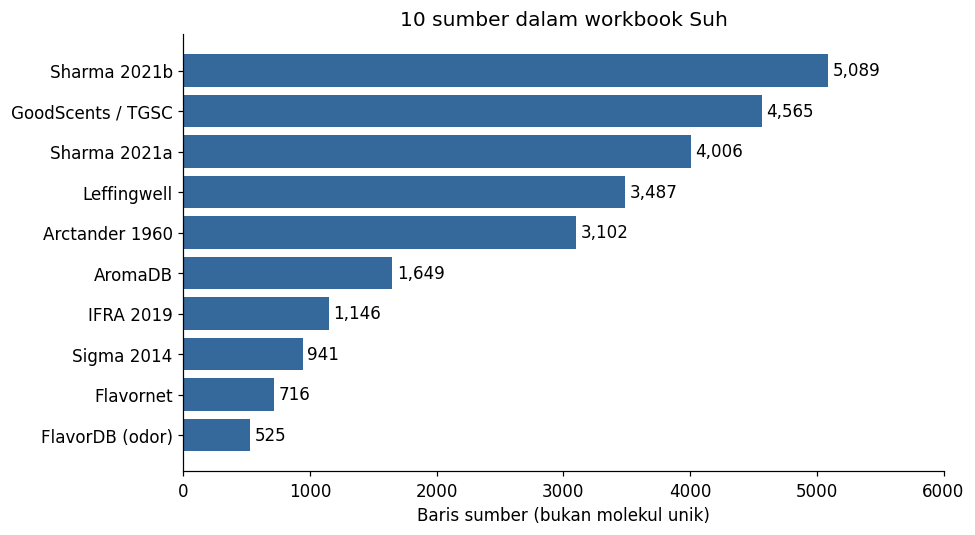

In [2]:
sources = pd.read_csv(output / 'source_inventory.csv')
display(sources)
fig, ax = plt.subplots(figsize=(9, 5))
chart = sources.sort_values('archived_rows')
ax.barh(chart.source_name, chart.archived_rows, color='#35689b')
ax.set(xlabel='Baris sumber (bukan molekul unik)', title='10 sumber dalam workbook Suh')
ax.set_xlim(0, chart.archived_rows.max() * 1.18)
for i, value in enumerate(chart.archived_rows):
    ax.text(value + 35, i, f'{value:,}', va='center')
fig.tight_layout()
plt.show()

## 3. Cleaning dan identitas
Deduplikasi string SMILES dan penghapusan nilai wajib kosong mengikuti sel 2 Suh. Nomor source_row disimpan. Slot aroma kosong tidak diimputasi.

Checkpoint sebelum split terdiri dari **8.700 baris**. Angka **8.681** muncul setelah filter strata langka, yang mengandung masalah indeks. V8 belum mengadopsinya sebagai data training.

In [3]:
display(pd.read_csv(output / 'preprocessing_stages.csv'))
display(pd.Series(audit['workbook'], dtype=object).loc[
    ['final_excel_rows', 'final_csv_rows',
     'csv_extra_duplicate_full_rows_without_molblock',
     'same_unique_record_content', 'same_after_author_smiles_deduplication']])
display(pd.read_csv(output / 'author_exclusions.csv').groupby('reason').size().rename('rows'))

,stage,rows
0,Author Dataset2 CSV,8806
1,Exact SMILES deduplication,8746
2,Required SMILES/MolBlock present,8700
3,At least one label: pre-split checkpoint,8700


final_excel_rows                                  8764
final_csv_rows                                    8806
csv_extra_duplicate_full_rows_without_molblock      42
same_unique_record_content                        True
same_after_author_smiles_deduplication            True
dtype: object

reason
duplicate_smiles_keep_first    60
missing_smiles_or_molblock     46
Name: rows, dtype: int64

## 4. Ekstraksi fitur dan target
SMILES → Morgan radius 2, 2048 bit, tanpa kiralitas + 8 RDKit berurutan seperti v7. Tidak ada scaling/imputasi. ST1024, MD8, dan FG20 acuan disimpan terpisah untuk audit. **558 struktur multikomponen** dipertahankan pada audit; kebijakan training belum disetujui.

In [4]:
with np.load(output / 'PREML_AUDIT_ONLY.npz', allow_pickle=False) as z:
    X, Y = z['X_v8_2056'], z['truth_200']
    descriptor_names, descriptor_values = z['descriptor_names'].tolist(), z['descriptors_8']
    assert X.shape[1] == 2056 and np.isfinite(X).all()
    assert np.isin(Y, [0, 1]).all()
    assert np.array_equal(z['source_row'], pd.read_csv(output / 'records.csv').source_row)
display(pd.DataFrame([
    {'matriks': 'V8 Morgan + 8', 'baris': X.shape[0], 'kolom': X.shape[1]},
    {'matriks': 'Target lengkap', 'baris': Y.shape[0], 'kolom': Y.shape[1]},
    {'matriks': 'ST Suh untuk audit', 'baris': X.shape[0], 'kolom': 1024}]))
display(pd.DataFrame(descriptor_values, columns=descriptor_names).describe(
    percentiles=[.01, .5, .99]).round(3))
print('D8 cocok dengan helper asli setelah urutan/float32:',
      audit['features']['d8_matches_author_after_order_and_float32_conversion'])
print('Encoding cocok dengan helper asli:',
      audit['features']['label_encoding_matches_author_helpers'])

,matriks,baris,kolom
0,V8 Morgan + 8,8700,2056
1,Target lengkap,8700,200
2,ST Suh untuk audit,8700,1024


,MolWt,MolLogP,NumHDonors,NumHAcceptors,TPSA,NumRotatableBonds,HeavyAtomCount,RingCount
count,8700.000,8700.000,8700.000,8700.000,8700.000,8700.000,8700.000,8700.000
mean,196.149,2.342,0.533,2.217,34.673,4.015,13.477,0.924
std,102.481,2.471,1.219,2.115,40.519,3.896,6.973,1.258
min,3.022,-43.248,0.000,0.000,0.000,0.000,0.000,0.000
1%,62.022,-7.334,0.000,0.000,0.000,0.000,3.000,0.000
50%,180.203,2.539,0.000,2.000,26.300,3.000,13.000,1.000
99%,561.041,7.159,5.000,11.000,201.670,18.000,36.000,5.000
max,2632.994,47.055,24.000,50.000,748.760,72.000,194.000,30.000


D8 cocok dengan helper asli setelah urutan/float32: True
Encoding cocok dengan helper asli: True


## 5. Distribusi seluruh label
**200 label** teramati disimpan. Ringkasan Suh memakai **100 label dengan >=30 kemunculan slot** sebelum filter strata. Label yang berulang dalam satu baris dihitung lebih dari satu pada aturan slot, tetapi satu kali dalam target biner. CSV menyimpan keduanya.

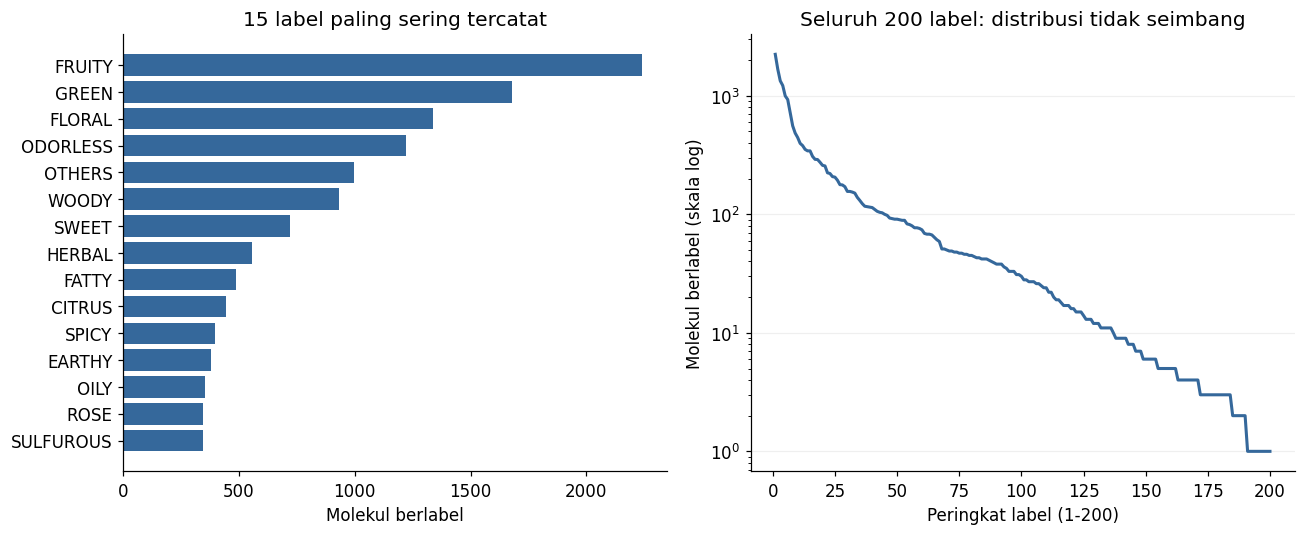

,label,record_positive_count,slot_occurrence_count
39,CITRONELLA,1,1
11,ARTEMISIA,1,1
181,TOFFEE,1,1
122,ORANGE,1,1
22,BUTTERSCOTCH,1,1
128,PEA,1,1
36,CHILLI-PEPPER,1,1
95,LEMONGRASS,1,1
87,INDOLIC,1,1
173,SWEET-PEA,1,1


Label ringkasan acuan: 100
Densitas positif: 0.012482


In [5]:
support = pd.read_csv(output / 'label_support.csv')
ordered = support.sort_values('record_positive_count', ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
top = ordered.head(15).iloc[::-1]
axes[0].barh(top.label, top.record_positive_count, color='#35689b')
axes[0].set(xlabel='Molekul berlabel', title='15 label paling sering tercatat')
axes[1].plot(np.arange(1, len(ordered)+1), ordered.record_positive_count.to_numpy(),
             color='#35689b', linewidth=2)
axes[1].set(xlabel='Peringkat label (1-200)', ylabel='Molekul berlabel (skala log)',
            title='Seluruh 200 label: distribusi tidak seimbang', yscale='log')
axes[1].grid(axis='y', alpha=.2)
fig.tight_layout()
plt.show()
display(ordered.tail(10)[['label', 'record_positive_count', 'slot_occurrence_count']])
print('Label ringkasan acuan:', int(support.author_summary_ge30_slots.sum()))
print('Densitas positif:', round(float(Y.mean()), 6))

## 6. Indeks split dan overlap
Tabel mengikuti perilaku kode Suh untuk **diagnosis saja**. Metadata setelah filter dan matriks sebelum filter dapat menunjuk molekul berbeda. **X dan Y masih saling berpasangan**; masalahnya adalah metadata/stratifikasi. Tidak ada koreksi atau split training baru.

In [6]:
split = audit['split_diagnostic']
display(pd.Series({
    'Posisi metadata/fitur berbeda': split['mismatched_source_row_positions'],
    'Strata berbeda dari baris fitur': split['mismatched_stratification_label_positions'],
    'Anggota kohor berbeda': split['actual_cohort_rows_outside_intended'],
    'Fingerprint 1024 bersama train-test': split['reference_fingerprint_overlap']['shared_keys'],
    'Fingerprint 2048 bersama train-test': split['v8_fingerprint_overlap']['shared_keys'],
    'Struktur multikomponen': audit['features']['multicomponent_records']}))
trace = pd.read_csv(output / 'REFERENCE_SPLIT_DIAGNOSTIC_ONLY.csv')
display(trace.loc[trace.intended_source_row != trace.actual_feature_source_row].head(6))
display(pd.DataFrame(audit['features']['smiles_molblock_structure_differences']))

Posisi metadata/fitur berbeda          7075
Strata berbeda dari baris fitur        6559
Anggota kohor berbeda                    19
Fingerprint 1024 bersama train-test     414
Fingerprint 2048 bersama train-test     414
Struktur multikomponen                  558
dtype: int64

,split_position,reference_partition_diagnostic,intended_preml_row,actual_feature_preml_row,intended_source_row,actual_feature_source_row,actual_label_source_row,intended_primary_label,actual_primary_label
1606,1606,train,1607,1606,1628,1627,1627,BLAND,PLUM
1607,1607,train,1608,1607,1629,1628,1628,ODORLESS,BLAND
1608,1608,train,1609,1608,1630,1629,1629,ODORLESS,ODORLESS
1609,1609,test,1610,1609,1631,1630,1630,ODORLESS,ODORLESS
1610,1610,train,1611,1610,1632,1631,1631,MILD,ODORLESS
1611,1611,train,1612,1611,1633,1632,1632,BLAND,MILD


,source_row,cid,smiles,parsed_molblock_smiles,action
0,4523,167583,[2HH],[H][2H],reported_only_no_repair


## 7. Kesimpulan
Kesamaan arsip dan encoding dapat dibuktikan. **Pre-ML tidak identik** karena fitur 2048 + 8 dipertahankan atas instruksi pengguna. Semua baseline dan tuned berikutnya harus menerima fitur yang sama.

Belum ada model V8 terlatih. Review koreksi indeks, split, multikomponen, dan batas reproduksi sumber pada V8_PREML_PLAN.md.

In [7]:
display(pd.read_csv(output / 'comparison_with_suh.csv')[['component', 'status']])
assert manifest['ready_for_ml'] is False
assert audit['training_started'] is False
assert audit['tuning_started'] is False
print('Audit selesai. Berhenti sebelum ML sesuai instruksi.')

,component,status
0,Dataset sumber,Sama pada arsip
1,Raw -> curated preparation,Belum direproduksi penuh
2,CSV -> pre-split checkpoint,Sama pada checkpoint
3,Features,Berbeda disengaja
4,Targets,Sama pada checkpoint
5,After singleton filter / split,STOP untuk ditinjau
6,Model,Subset model acuan
7,Hyperparameter,Belum dijalankan
8,Tuning,Ditunda
9,Evaluation,Belum dijalankan


Audit selesai. Berhenti sebelum ML sesuai instruksi.
